# Projet Leyenda — Deliverable 2: Image denoising with a convolutional autoencoder (CAE)

**Team:** Haytam El hilali / Felipe Lobos / Fernanda Gentil.

TouNum's digitized archives contain photographs degraded by noise. Before these images
reach the captioning service, the noise must be removed. This notebook builds that
cleaning step with a **convolutional autoencoder (CAE)**.

## 1. File loading code

This section inspects the available dataset, checks image dimensions and colour modes, and creates a reproducible training/validation split.
The dataset contains 148 noisy RGB images and no clean reference images. We use 118 images for training and 30 for validation.

In [1]:
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image

print("TensorFlow:", tf.__version__)

TensorFlow: 2.22.0-rc0


In [2]:
# Inventario del dataset
data_dir = Path(
    r"C:\Users\Felipe\Documents\DataScience\Deliverable material 2\Dataset"
)

if not data_dir.exists():
    raise FileNotFoundError(f"No se encontró la carpeta: {data_dir}")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

image_paths = sorted(
    path for path in data_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
)

print(f"Carpeta del dataset: {data_dir}")
print(f"Imágenes encontradas: {len(image_paths)}")
print("Extensiones:", Counter(path.suffix.lower() for path in image_paths))
print("Primeros archivos:", [path.name for path in image_paths[:10]])

Carpeta del dataset: C:\Users\Felipe\Documents\DataScience\Deliverable material 2\Dataset
Imágenes encontradas: 148
Extensiones: Counter({'.jpg': 148})
Primeros archivos: ['noisy_001.jpg', 'noisy_002.jpg', 'noisy_003.jpg', 'noisy_004.jpg', 'noisy_005.jpg', 'noisy_006.jpg', 'noisy_007.jpg', 'noisy_008.jpg', 'noisy_009.jpg', 'noisy_010.jpg']


Dimensiones más frecuentes: [((640, 480), 41), ((640, 427), 16), ((480, 640), 7), ((500, 375), 6), ((640, 428), 5), ((640, 425), 5), ((640, 426), 4), ((427, 640), 4), ((500, 333), 4), ((640, 463), 3)]
Modos de color: Counter({'RGB': 148})


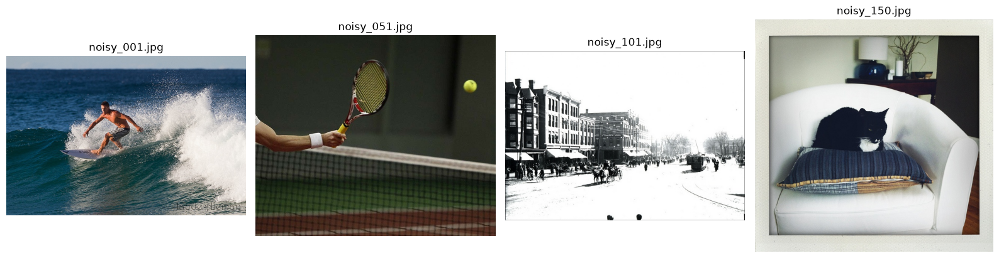

In [3]:
# Dimensiones, modo de color y primera vista
sizes = Counter()
modes = Counter()

for path in image_paths:
    with Image.open(path) as img:
        sizes[img.size] += 1
        modes[img.mode] += 1

print("Dimensiones más frecuentes:", sizes.most_common(10))
print("Modos de color:", modes)

sample_indices = sorted(set([0, len(image_paths)//3, 2*len(image_paths)//3, len(image_paths)-1]))

fig, axes = plt.subplots(1, len(sample_indices), figsize=(16, 4))

for ax, index in zip(axes, sample_indices):
    with Image.open(image_paths[index]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(image_paths[index].name)
    ax.axis("off")

plt.tight_layout()
plt.show()

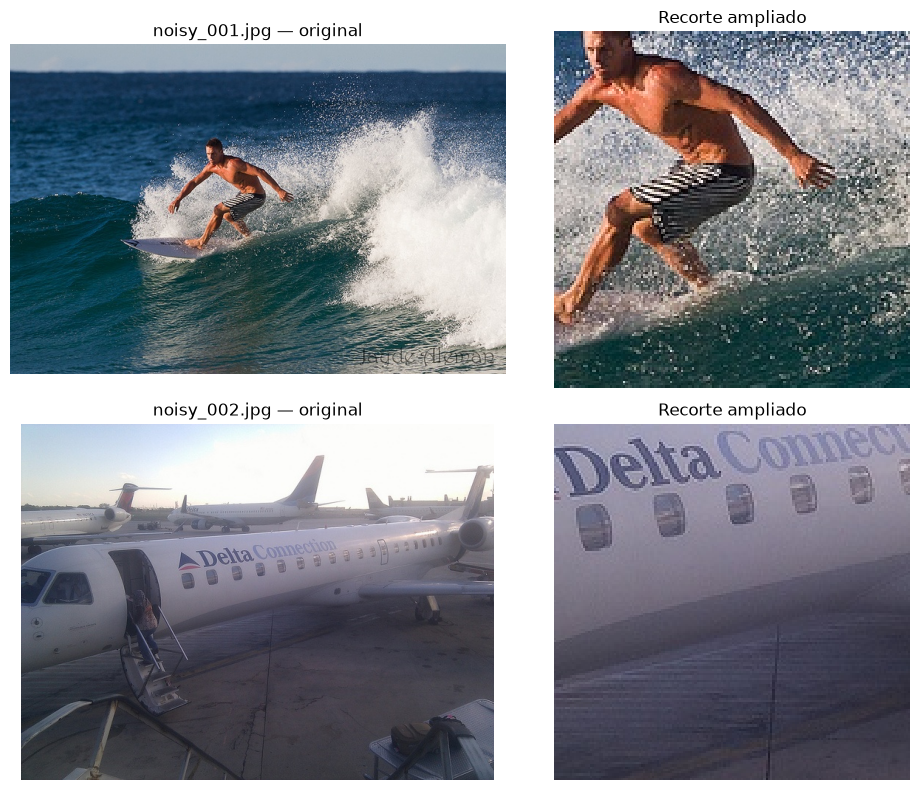

In [4]:
# Zoom sobre el ruido: recorte ampliado de dos imágenes
example_names = ["noisy_001.jpg", "noisy_002.jpg"]

fig, axes = plt.subplots(len(example_names), 2, figsize=(10, 8))

for row, name in enumerate(example_names):
    path = next((p for p in image_paths if p.name == name), None)

    if path is None:
        print(f"No se encontró: {name}")
        continue

    with Image.open(path) as img:
        img = img.convert("RGB")
        width, height = img.size

        crop_w = min(160, width)
        crop_h = min(160, height)
        left = (width - crop_w) // 2
        top = (height - crop_h) // 2
        crop = img.crop((left, top, left + crop_w, top + crop_h))

        axes[row, 0].imshow(img)
        axes[row, 0].set_title(f"{name} — original")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(crop, interpolation="nearest")
        axes[row, 1].set_title("Recorte ampliado")
        axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

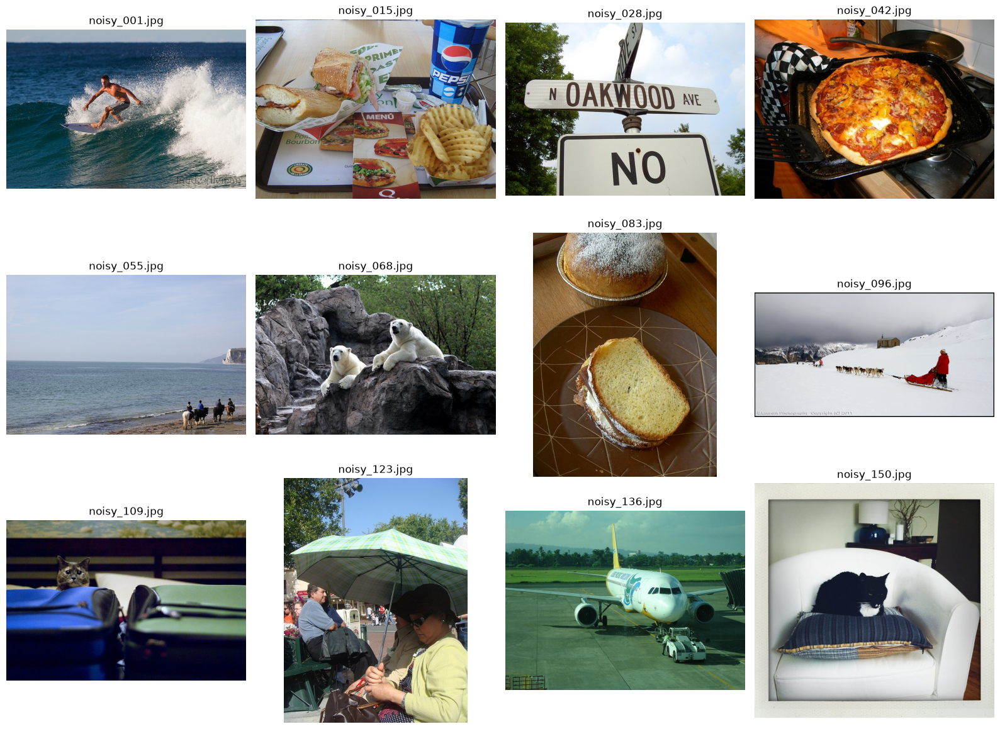

In [5]:
# Vista general: 12 imágenes repartidas por el dataset
n_samples = min(12, len(image_paths))
sample_indices = np.linspace(0, len(image_paths) - 1, n_samples, dtype=int)

cols = 4
rows = (n_samples + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
axes = np.array(axes).reshape(-1)

for ax, index in zip(axes, sample_indices):
    path = image_paths[index]
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(path.name)
    ax.axis("off")

for ax in axes[n_samples:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Tamaños mínimos: confirma que todas las imágenes admiten recortes de 128×128
image_sizes = []

for path in image_paths:
    with Image.open(path) as img:
        image_sizes.append((path.name, img.width, img.height))

min_width = min(width for _, width, _ in image_sizes)
min_height = min(height for _, _, height in image_sizes)

print(f"Ancho mínimo: {min_width}")
print(f"Alto mínimo: {min_height}")
print("Imágenes más pequeñas:")
for name, width, height in sorted(image_sizes, key=lambda item: item[1] * item[2])[:10]:
    print(f"{name}: {width} × {height}")

Ancho mínimo: 333
Alto mínimo: 233
Imágenes más pequeñas:
noisy_103.jpg: 480 × 252
noisy_092.jpg: 640 × 233
noisy_130.jpg: 500 × 299
noisy_047.jpg: 640 × 258
noisy_053.jpg: 333 × 500
noisy_060.jpg: 500 × 333
noisy_094.jpg: 500 × 333
noisy_128.jpg: 500 × 333
noisy_140.jpg: 500 × 333
noisy_147.jpg: 333 × 500


### 1.1 Train / validation split

We split the images into a **training set** (80 %) and a **validation set** (20 %).
The validation set measures the performance of the autoencoder on images it has never
seen. The fixed seed makes the split reproducible.





In [7]:
# División reproducible: 80 % para entrenar, 20 % para validar
rng = np.random.default_rng(42)
indices = rng.permutation(len(image_paths))
n_val = round(0.20 * len(image_paths))

val_indices = indices[:n_val]
train_indices = indices[n_val:]

train_paths = [image_paths[i] for i in train_indices]
val_paths = [image_paths[i] for i in val_indices]

print(f"Imágenes para entrenamiento: {len(train_paths)}")
print(f"Imágenes para validación: {len(val_paths)}")
print("Ejemplos de validación:", [p.name for p in val_paths[:5]])

Imágenes para entrenamiento: 118
Imágenes para validación: 30
Ejemplos de validación: ['noisy_022.jpg', 'noisy_091.jpg', 'noisy_004.jpg', 'noisy_132.jpg', 'noisy_058.jpg']


## 2. Denoising code

### Strategy: self-supervised masked denoising

The dataset contains noisy images but no clean reference images. Therefore, we cannot train the model using noisy-clean image pairs.

Instead, we will use a self-supervised approach: hide selected pixels from the input image and train a Convolutional Autoencoder (CAE) to predict their values from the surrounding context. The loss will be calculated only on the hidden pixels.

This approach can reduce noise when the noise is sufficiently independent from one pixel to another. Its effectiveness depends on the type of noise in the images, so we will inspect the results visually. We will not calculate PSNR or SSIM against clean images because no clean references are available.

In [8]:
# Denoising code — 1. Preparar imágenes RGB de 128 × 128

IMAGE_SIZE = 128

def load_rgb_images(paths):
    images = []

    for path in paths:
        with Image.open(path) as img:
            img = img.convert("RGB")

            # Recorte central, manteniendo la resolución original
            width, height = img.size
            left = (width - IMAGE_SIZE) // 2
            top = (height - IMAGE_SIZE) // 2
            img = img.crop((
                left,
                top,
                left + IMAGE_SIZE,
                top + IMAGE_SIZE
            ))

            # Convertir a valores float entre 0 y 1
            image_array = np.asarray(img, dtype=np.float32) / 255.0
            images.append(image_array)

    return np.stack(images)


train_images = load_rgb_images(train_paths)
val_images = load_rgb_images(val_paths)

print("Forma de train_images:", train_images.shape)
print("Forma de val_images:", val_images.shape)
print("Rango de píxeles:", train_images.min(), "a", train_images.max())

Forma de train_images: (118, 128, 128, 3)
Forma de val_images: (30, 128, 128, 3)
Rango de píxeles: 0.0 a 1.0


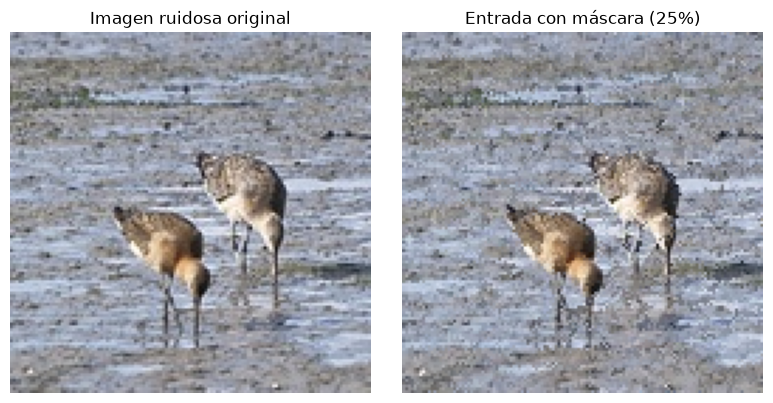

Forma de una entrada enmascarada: (128, 128, 3)
Forma del objetivo + máscara: (128, 128, 4)


In [9]:
# Denoising code — 2. Máscara aleatoria y masked MSE

MASK_RATE = 0.25  # Se oculta el 5 % de los píxeles
BATCH_SIZE = 8


def choose_random_neighbor(image, seed=None):
    # Desplazamientos de los 8 vecinos, evitando el píxel central
    offsets = tf.constant(
        [
            [-1, -1], [-1, 0], [-1, 1],
            [ 0, -1],           [ 0, 1],
            [ 1, -1], [ 1, 0],  [ 1, 1]
        ],
        dtype=tf.int32
    )

    height_width = tf.shape(image)[:2]

    if seed is None:
        choices = tf.random.uniform(
            shape=height_width,
            minval=0,
            maxval=8,
            dtype=tf.int32
        )
    else:
        choices = tf.random.stateless_uniform(
            shape=height_width,
            seed=seed,
            minval=0,
            maxval=8,
            dtype=tf.int32
        )

    # Crear las ocho versiones desplazadas y elegir un vecino
    # independientemente en cada posición espacial.
    neighbor_images = tf.stack(
        [
            tf.roll(image, shift=offset, axis=[0, 1])
            for offset in tf.unstack(offsets)
        ],
        axis=0
    )

    selectors = tf.one_hot(
        choices,
        depth=8,
        axis=0,
        dtype=image.dtype
    )[..., tf.newaxis]

    return tf.reduce_sum(neighbor_images * selectors, axis=0)


def create_masked_sample(image):
    # Máscara espacial compartida por los tres canales RGB
    mask = tf.cast(
        tf.random.uniform(tf.shape(image)[:2]) < MASK_RATE,
        image.dtype
    )
    mask = tf.expand_dims(mask, axis=-1)

    # Cada píxel oculto se reemplaza por un vecino elegido al azar
    neighbor_image = choose_random_neighbor(image)
    masked_image = image * (1.0 - mask) + neighbor_image * mask

    # La pérdida se calculará solo donde mask == 1
    target_with_mask = tf.concat([image, mask], axis=-1)

    return masked_image, target_with_mask


def create_fixed_masked_sample(image, index):
    # Máscara reproducible para cada imagen de validación
    image_seed = tf.stack([
        tf.constant(2026, dtype=tf.int32),
        tf.cast(index, tf.int32)
    ])

    mask = tf.cast(
        tf.random.stateless_uniform(
            shape=tf.shape(image)[:2],
            seed=image_seed
        ) < MASK_RATE,
        image.dtype
    )
    mask = tf.expand_dims(mask, axis=-1)

    neighbor_seed = image_seed + tf.constant([17, 29], dtype=tf.int32)
    neighbor_image = choose_random_neighbor(image, seed=neighbor_seed)

    masked_image = image * (1.0 - mask) + neighbor_image * mask
    target_with_mask = tf.concat([image, mask], axis=-1)

    return masked_image, target_with_mask


def masked_mse(target_with_mask, prediction):
    # Los primeros 3 canales son la imagen objetivo RGB
    target = target_with_mask[..., :3]

    # El último canal indica qué píxeles fueron ocultados
    mask = target_with_mask[..., 3:4]

    squared_error = tf.square(target - prediction) * mask

    # Normalizamos por el número de píxeles ocultos y canales RGB
    numerator = tf.reduce_sum(squared_error, axis=[1, 2, 3])
    denominator = (
        tf.reduce_sum(mask, axis=[1, 2, 3]) * 3.0
        + tf.keras.backend.epsilon()
    )

    return numerator / denominator


# Comprobación visual de una máscara en una imagen de entrenamiento
example_masked, example_target = create_masked_sample(
    tf.convert_to_tensor(train_images[0])
)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(train_images[0])
axes[0].set_title("Imagen ruidosa original")
axes[0].axis("off")

axes[1].imshow(example_masked.numpy())
axes[1].set_title(f"Entrada con máscara ({MASK_RATE:.0%})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Forma de una entrada enmascarada:", example_masked.shape)
print("Forma del objetivo + máscara:", example_target.shape)

In [10]:
# Denoising code — 3. Arquitectura del Convolutional Autoencoder (CAE)

inputs = tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name="noisy_rgb_image")

# Encoder: extrae características y reduce las dimensiones espaciales
x = tf.keras.layers.Conv2D(
    32, kernel_size=3, padding="same", activation="relu"
)(inputs)
x = tf.keras.layers.MaxPooling2D(pool_size=2, padding="same")(x)

x = tf.keras.layers.Conv2D(
    64, kernel_size=3, padding="same", activation="relu"
)(x)
x = tf.keras.layers.MaxPooling2D(pool_size=2, padding="same")(x)

# Representación comprimida
x = tf.keras.layers.Conv2D(
    128, kernel_size=3, padding="same", activation="relu",
    name="bottleneck"
)(x)

# Decoder: reconstruye las dimensiones espaciales
x = tf.keras.layers.UpSampling2D(size=2)(x)
x = tf.keras.layers.Conv2D(
    64, kernel_size=3, padding="same", activation="relu"
)(x)

x = tf.keras.layers.UpSampling2D(size=2)(x)
x = tf.keras.layers.Conv2D(
    32, kernel_size=3, padding="same", activation="relu"
)(x)

# Reconstrucción RGB con valores entre 0 y 1
outputs = tf.keras.layers.Conv2D(
    3, kernel_size=3, padding="same", activation="sigmoid",
    name="reconstructed_rgb_image"
)(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs, name="masked_denoising_cae")

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=masked_mse
)

model.summary()

Model: "masked_denoising_cae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ noisy_rgb_image (InputLayer)    │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Conv2D)             │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_rgb_image         │ (None, 128, 128, 3)    │           867 │
│ (Conv2D)                        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 186,371 (728.01 KB)

 Trainable params: 186,371 (728.01 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Denoising code — 4. Datasets con validación reproducible

tf.random.set_seed(42)
AUTOTUNE = tf.data.AUTOTUNE

# Entrenamiento: la máscara y el vecino varían durante el entrenamiento
train_dataset = (
    tf.data.Dataset.from_tensor_slices(train_images)
    .shuffle(
        buffer_size=len(train_images),
        seed=42,
        reshuffle_each_iteration=True
    )
    .map(create_masked_sample, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_indices = np.arange(len(val_images), dtype=np.int32)

# Validación: máscaras fijas y reproducibles
val_dataset = (
    tf.data.Dataset.from_tensor_slices((val_images, val_indices))
    .map(create_fixed_masked_sample, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Comprobación de las dimensiones de un batch
for masked_batch, target_batch in val_dataset.take(1):
    print("Forma de entrada:", masked_batch.shape)
    print("Forma del objetivo + máscara:", target_batch.shape)
    print(
        "Proporción enmascarada:",
        f"{tf.reduce_mean(target_batch[..., 3]).numpy():.2%}"
    )

Forma de entrada: (8, 128, 128, 3)
Forma del objetivo + máscara: (8, 128, 128, 4)
Proporción enmascarada: 25.04%


In [12]:
# Denoising code — 4b. Data augmentation para el entrenamiento

def augment_image(image):
    image = tf.image.random_flip_left_right(image, seed=42)
    image = tf.image.random_flip_up_down(image, seed=43)
    rotations = tf.random.uniform([], minval=0, maxval=4, dtype=tf.int32, seed=44)
    image = tf.image.rot90(image, k=rotations)
    return image


train_dataset_aug = (
    tf.data.Dataset.from_tensor_slices(train_images)
    .shuffle(
        buffer_size=len(train_images),
        seed=42,
        reshuffle_each_iteration=True
    )
    .map(
        lambda img: create_masked_sample(augment_image(img)),
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Dataset con augmentation listo:", train_dataset_aug)

Dataset con augmentation listo: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 128, 128, 4), dtype=tf.float32, name=None))>


In [13]:
# Denoising code — 5. Entrenamiento del CAE

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=100,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100


C:\Users\Felipe\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 542ms/step - loss: 0.0711 - val_loss: 0.0634
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 367ms/step - loss: 0.0428 - val_loss: 0.0258
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 348ms/step - loss: 0.0249 - val_loss: 0.0135
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 309ms/step - loss: 0.0159 - val_loss: 0.0107
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 307ms/step - loss: 0.0134 - val_loss: 0.0095
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 298ms/step - loss: 0.0108 - val_loss: 0.0080
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 329ms/step - loss: 0.0096 - val_loss: 0.0073
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 315ms/step - loss: 0.0089 - val_loss: 0.0067
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 343ms/step - loss: 0.0084 - val_loss: 0.0071
Epoch 10/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 381ms/step - loss: 0.0086 - val_loss: 0.0064
Epoch 11/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 327ms/step - loss: 0.0082 - val_loss: 0.0065
Epoch 12/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 314ms/ste

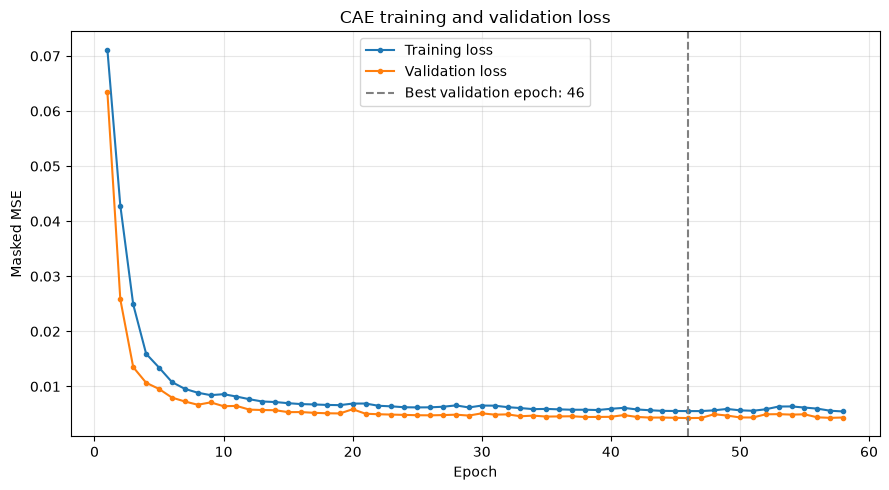

Mejor época de validación: 46
Mejor validation loss: 0.0043


In [14]:
# Denoising code — 6. Curvas de pérdida

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(train_loss) + 1)

best_epoch = int(np.argmin(val_loss)) + 1
best_val_loss = min(val_loss)

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, marker="o", markersize=3, label="Training loss")
plt.plot(epochs, val_loss, marker="o", markersize=3, label="Validation loss")
plt.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best validation epoch: {best_epoch}"
)

plt.title("CAE training and validation loss")
plt.xlabel("Epoch")
plt.ylabel("Masked MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mejor época de validación: {best_epoch}")
print(f"Mejor validation loss: {best_val_loss:.4f}")

## 3. Case study

### Objective and evaluation protocol

This case study compares three trained models: the baseline CAE v1, the U-Net-style CAE v2 with ReLU, and the U-Net-style CAE v2 with SiLU.

The evaluation uses validation images that were excluded from training. These images were also used to monitor training and guide model development; therefore, they do not constitute an independent test set.

Quantitative evaluation uses masked MSE with fixed validation masks and reproducible neighbour replacements. This measures prediction error at hidden positions against the observed noisy pixel values, not restoration error against clean images.

For the final visual comparison, all three models receive the same masked inputs. Predictions are accumulated only at masked positions and averaged over 200 masking passes.

The comparison examines apparent noise, edge preservation, fine detail and over-smoothing. Pixel coverage indicates how many positions received predictions; it is not a measure of denoising quality.

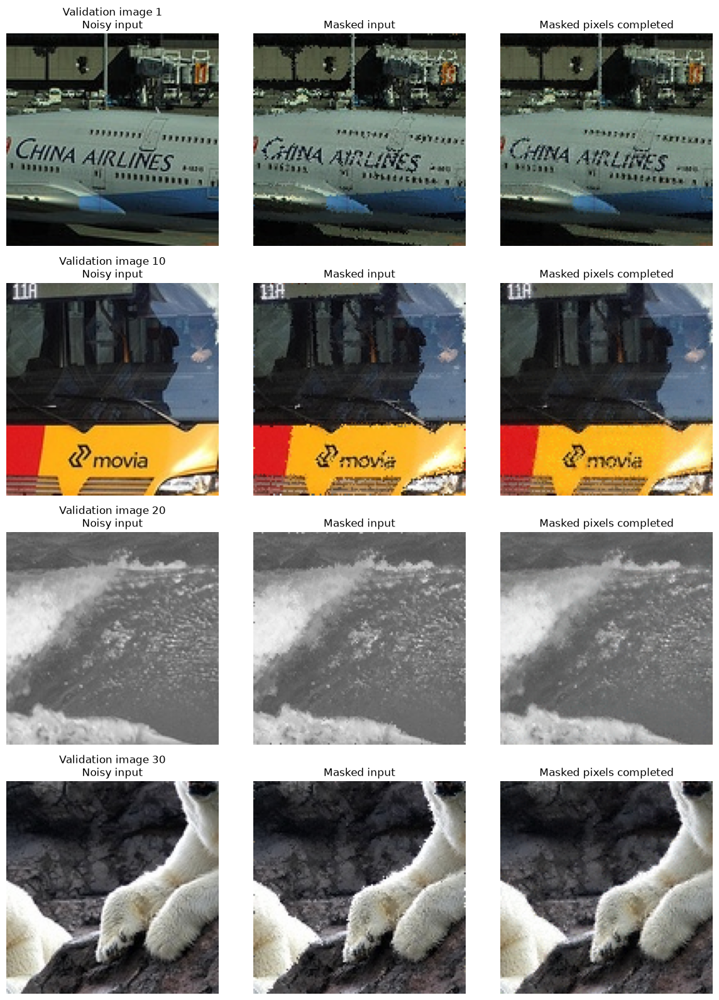

In [15]:
# Case study — comparar imágenes de validación y completar píxeles enmascarados

n_examples = min(4, len(val_images))
example_indices = np.linspace(
    0, len(val_images) - 1, n_examples, dtype=int
)

fig, axes = plt.subplots(n_examples, 3, figsize=(12, 4 * n_examples))

if n_examples == 1:
    axes = np.expand_dims(axes, axis=0)

for row, index in enumerate(example_indices):
    original = tf.convert_to_tensor(val_images[index])

    # Crear una máscara nueva para esta prueba
    masked_input, target_with_mask = create_masked_sample(original)
    mask = target_with_mask[..., 3:4]

    # Predecir y reemplazar solo los píxeles ocultos
    prediction = model(
        tf.expand_dims(masked_input, axis=0),
        training=False
    )[0]

    completed = (
        original * (1.0 - mask)
        + prediction * mask
    )

    axes[row, 0].imshow(original.numpy())
    axes[row, 0].set_title(f"Validation image {index + 1}\nNoisy input")

    axes[row, 1].imshow(masked_input.numpy())
    axes[row, 1].set_title("Masked input")

    axes[row, 2].imshow(tf.clip_by_value(completed, 0.0, 1.0).numpy())
    axes[row, 2].set_title("Masked pixels completed")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

Imagen 1: 100.00% de los píxeles recibieron predicciones
Imagen 10: 100.00% de los píxeles recibieron predicciones
Imagen 20: 100.00% de los píxeles recibieron predicciones
Imagen 30: 100.00% de los píxeles recibieron predicciones


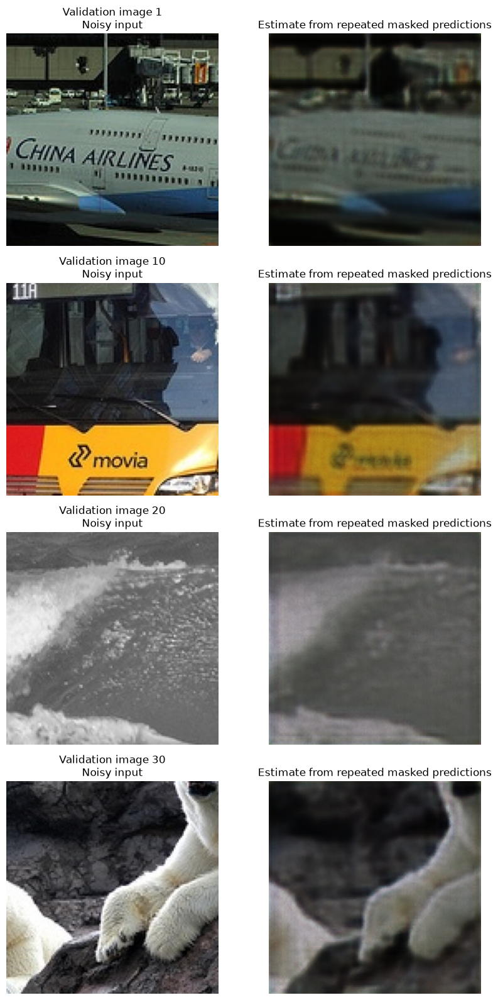

In [16]:
# Case study — estimación de todos los píxeles con máscaras repetidas

def estimate_image_with_repeated_masks(image, n_passes=200, batch_size=16):
    image = np.asarray(image, dtype=np.float32)
    height, width, channels = image.shape
    rng = np.random.default_rng(42)

    # Cada máscara oculta el mismo porcentaje usado durante el entrenamiento
    masks = (
        rng.random((n_passes, height, width, 1)) < MASK_RATE
    ).astype(np.float32)

    # El modelo solo puede predecir los píxeles ocultos en cada pasada
    masked_inputs = image[None, ...] * (1.0 - masks)

    predictions = model.predict(
        masked_inputs,
        batch_size=batch_size,
        verbose=0
    )

    # Acumular predicciones únicamente donde el píxel estaba oculto
    prediction_sum = np.sum(predictions * masks, axis=0)
    prediction_count = np.sum(masks, axis=0)

    # Promediar las predicciones; si algún píxel nunca fue ocultado,
    # conservar allí el valor original
    averaged_predictions = prediction_sum / np.maximum(prediction_count, 1.0)

    result = image.copy()
    covered = prediction_count[..., 0] > 0
    result[covered] = averaged_predictions[covered]

    return np.clip(result, 0.0, 1.0), prediction_count


n_examples = min(4, len(val_images))
example_indices = np.linspace(
    0, len(val_images) - 1, n_examples, dtype=int
)

fig, axes = plt.subplots(n_examples, 2, figsize=(9, 4 * n_examples))

if n_examples == 1:
    axes = np.expand_dims(axes, axis=0)

for row, index in enumerate(example_indices):
    original = val_images[index]

    estimate, prediction_count = estimate_image_with_repeated_masks(
        original,
        n_passes=200
    )

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"Validation image {index + 1}\nNoisy input")

    axes[row, 1].imshow(estimate)
    axes[row, 1].set_title("Estimate from repeated masked predictions")

    for ax in axes[row]:
        ax.axis("off")

    covered_fraction = np.mean(prediction_count[..., 0] > 0)
    print(
        f"Imagen {index + 1}: "
        f"{covered_fraction:.2%} de los píxeles recibieron predicciones"
    )

plt.tight_layout()
plt.show()

### Case study observations

The estimates from repeated masked predictions are visibly smoother than the noisy inputs, but they also lose fine details and edge sharpness. Therefore, this experiment does not show a clear improvement in image quality.

The reported 100% coverage means that every pixel received at least one prediction across the repeated masking passes. It is a coverage result, not a denoising-quality score.

Because no clean reference images are available, we cannot claim quantitative restoration improvement using PSNR or SSIM. The current method should be reported as a self-supervised experiment with visible over-smoothing and important limitations.

In [17]:
# Denoising code — Modelo v2: CAE con conexiones tipo U-Net

inputs_v2 = tf.keras.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    name="noisy_rgb_image_v2"
)

# Encoder
enc1 = tf.keras.layers.Conv2D(
    32, kernel_size=3, padding="same", activation="relu"
)(inputs_v2)
enc1 = tf.keras.layers.Conv2D(
    32, kernel_size=3, padding="same", activation="relu"
)(enc1)
pool1 = tf.keras.layers.MaxPooling2D(pool_size=2, padding="same")(enc1)

enc2 = tf.keras.layers.Conv2D(
    64, kernel_size=3, padding="same", activation="relu"
)(pool1)
enc2 = tf.keras.layers.Conv2D(
    64, kernel_size=3, padding="same", activation="relu"
)(enc2)
pool2 = tf.keras.layers.MaxPooling2D(pool_size=2, padding="same")(enc2)

# Bottleneck
bottleneck = tf.keras.layers.Conv2D(
    128, kernel_size=3, padding="same", activation="relu"
)(pool2)
bottleneck = tf.keras.layers.Conv2D(
    128, kernel_size=3, padding="same", activation="relu"
)(bottleneck)

# Decoder con conexiones de características del encoder
up2 = tf.keras.layers.UpSampling2D(size=2)(bottleneck)
up2 = tf.keras.layers.Concatenate()([up2, enc2])
dec2 = tf.keras.layers.Conv2D(
    64, kernel_size=3, padding="same", activation="relu"
)(up2)
dec2 = tf.keras.layers.Conv2D(
    64, kernel_size=3, padding="same", activation="relu"
)(dec2)

up1 = tf.keras.layers.UpSampling2D(size=2)(dec2)
up1 = tf.keras.layers.Concatenate()([up1, enc1])
dec1 = tf.keras.layers.Conv2D(
    32, kernel_size=3, padding="same", activation="relu"
)(up1)
dec1 = tf.keras.layers.Conv2D(
    32, kernel_size=3, padding="same", activation="relu"
)(dec1)

outputs_v2 = tf.keras.layers.Conv2D(
    3,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="reconstructed_rgb_image_v2"
)(dec1)

model_v2 = tf.keras.Model(
    inputs=inputs_v2,
    outputs=outputs_v2,
    name="masked_denoising_unet_v2"
)

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=masked_mse
)

model_v2.summary()

Model: "masked_denoising_unet_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ noisy_rgb_image_v2  │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 128,  │        896 │ noisy_rgb_image_… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_4[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 64, 64,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_6[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 32, 32,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_3[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_8[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_2     │ (None, 64, 64,    │          0 │ conv2d_9[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d_2[… │
│ (Concatenate)       │ 192)              │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 64, 64,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_10[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 128, 128,  │          0 │ conv2d_11[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128,  │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 96)               │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 128, 128,  │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 128, 128,  │      9,248 │ conv2d_12[0][0] 

 Total params: 472,387 (1.80 MB)

 Trainable params: 472,387 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Denoising code — CAE v2 con SiLU (swish) en las capas ocultas

def conv_act_block(x, filters, name, activation="silu"):
    x = tf.keras.layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        name=f"{name}_conv"
    )(x)
    return tf.keras.layers.Activation(
        activation,
        name=f"{name}_act"
    )(x)


inputs_silu = tf.keras.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    name="noisy_rgb_image_silu"
)

# Encoder
enc1 = conv_act_block(inputs_silu, 32, "enc1_a")
enc1 = conv_act_block(enc1, 32, "enc1_b")
pool1 = tf.keras.layers.MaxPooling2D(pool_size=2, padding="same")(enc1)

enc2 = conv_act_block(pool1, 64, "enc2_a")
enc2 = conv_act_block(enc2, 64, "enc2_b")
pool2 = tf.keras.layers.MaxPooling2D(pool_size=2, padding="same")(enc2)

# Bottleneck
bottleneck = conv_act_block(pool2, 128, "bottleneck_a")
bottleneck = conv_act_block(bottleneck, 128, "bottleneck_b")

# Decoder con conexiones tipo U-Net
up2 = tf.keras.layers.UpSampling2D(size=2)(bottleneck)
up2 = tf.keras.layers.Concatenate()([up2, enc2])
dec2 = conv_act_block(up2, 64, "dec2_a")
dec2 = conv_act_block(dec2, 64, "dec2_b")

up1 = tf.keras.layers.UpSampling2D(size=2)(dec2)
up1 = tf.keras.layers.Concatenate()([up1, enc1])
dec1 = conv_act_block(up1, 32, "dec1_a")
dec1 = conv_act_block(dec1, 32, "dec1_b")

# Salida sigmoid: píxeles normalizados entre 0 y 1
outputs_silu = tf.keras.layers.Conv2D(
    3,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="reconstructed_rgb_silu"
)(dec1)

model_v2_silu = tf.keras.Model(
    inputs=inputs_silu,
    outputs=outputs_silu,
    name="masked_denoising_unet_silu"
)

model_v2_silu.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=masked_mse
)

model_v2_silu.summary()

Model: "masked_denoising_unet_silu"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ noisy_rgb_image_si… │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_a_conv         │ (None, 128, 128,  │        896 │ noisy_rgb_image_… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_a_act          │ (None, 128, 128,  │          0 │ enc1_a_conv[0][0] │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_b_conv         │ (None, 128, 128,  │      9,248 │ enc1_a_act[0][0]  │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_b_act          │ (None, 128, 128,  │          0 │ enc1_b_conv[0][0] │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 64, 64,    │          0 │ enc1_b_act[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_a_conv         │ (None, 64, 64,    │     18,496 │ max_pooling2d_4[… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_a_act          │ (None, 64, 64,    │          0 │ enc2_a_conv[0][0] │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_b_conv         │ (None, 64, 64,    │     36,928 │ enc2_a_act[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_b_act          │ (None, 64, 64,    │          0 │ enc2_b_conv[0][0] │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 32, 32,    │          0 │ enc2_b_act[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_a_conv   │ (None, 32, 32,    │     73,856 │ max_pooling2d_5[… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_a_act    │ (None, 32, 32,    │          0 │ bottleneck_a_con… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_b_conv   │ (None, 32, 32,    │    147,584 │ bottleneck_a_act… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_b_act    │ (None, 32, 32,    │          0 │ bottleneck_b_con… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_4     │ (None, 64, 64,    │          0 │ bottleneck_b_act… │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 64, 64,    │          0 │ up_sampling2d_4[

 Total params: 472,387 (1.80 MB)

 Trainable params: 472,387 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# Denoising code — Entrenamiento de SiLU con EarlyStopping

early_stopping_silu = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

history_v2_silu = model_v2_silu.fit(
    train_dataset_aug,
    validation_data=val_dataset,
    epochs=100,
    callbacks=[early_stopping_silu],
    verbose=1
)

print(
    "Mejor masked validation loss de SiLU:",
    f"{min(history_v2_silu.history['val_loss']):.6f}"
)

Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 868ms/step - loss: 0.0694 - val_loss: 0.0686
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 755ms/step - loss: 0.0439 - val_loss: 0.0230
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 723ms/step - loss: 0.0165 - val_loss: 0.0118
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 749ms/step - loss: 0.0116 - val_loss: 0.0079
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 779ms/step - loss: 0.0089 - val_loss: 0.0070
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 753ms/step - loss: 0.0083 - val_loss: 0.0067
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 765ms/step - loss: 0.0080 - val_loss: 0.0065
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 800ms/step - loss: 0.0079 - val_loss: 0.0063
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 758ms/step - loss: 0.0078 - val_loss: 0.0063
Epoch 10/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 813ms/step - loss: 0.0078 - val_loss: 0.0061
Epoch 11/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 798ms/step - loss: 0.0073 - val_loss: 0.0059
Epoch 12/100
15/15 ━━━━━━━━━━━

CAE v2 (ReLU) : 0.075269
CAE v2 (SiLU) : 0.003083


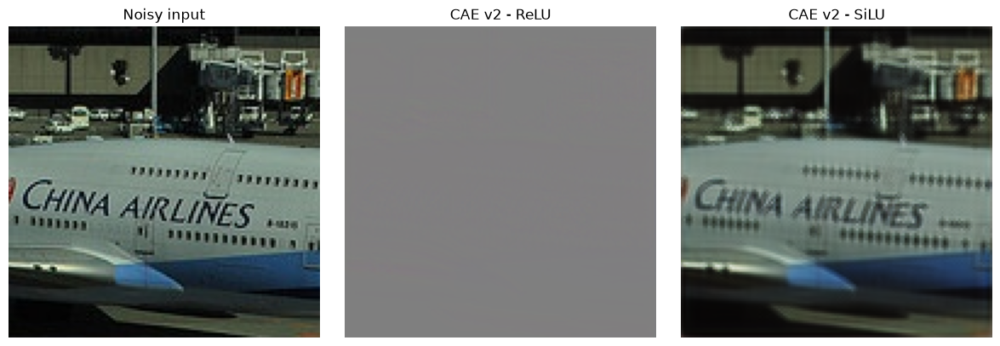

In [20]:
# Comparación con validación fija (25 % de máscara)
print(f"CAE v2 (ReLU) : {model_v2.evaluate(val_dataset, verbose=0):.6f}")
print(f"CAE v2 (SiLU) : {model_v2_silu.evaluate(val_dataset, verbose=0):.6f}")

# Vista rápida: entrada vs ReLU vs SiLU
sample = val_images[0:1]
recon_relu = model_v2.predict(sample, verbose=0)[0]
recon_silu = model_v2_silu.predict(sample, verbose=0)[0]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(
    axes,
    [sample[0], recon_relu, recon_silu],
    ["Noisy input", "CAE v2 - ReLU", "CAE v2 - SiLU"]
):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [21]:
# Denoising code — CAE v2 con LeakyReLU en las capas ocultas

def conv_leaky_block(x, filters, name):
    x = tf.keras.layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        name=f"{name}_conv"
    )(x)
    return tf.keras.layers.LeakyReLU(
        negative_slope=0.1,
        name=f"{name}_leaky_relu"
    )(x)


inputs_leaky = tf.keras.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    name="noisy_rgb_image_leaky"
)

# Encoder
enc1 = conv_leaky_block(inputs_leaky, 32, "enc1_a")
enc1 = conv_leaky_block(enc1, 32, "enc1_b")
pool1 = tf.keras.layers.MaxPooling2D(
    pool_size=2, padding="same"
)(enc1)

enc2 = conv_leaky_block(pool1, 64, "enc2_a")
enc2 = conv_leaky_block(enc2, 64, "enc2_b")
pool2 = tf.keras.layers.MaxPooling2D(
    pool_size=2, padding="same"
)(enc2)

# Bottleneck
bottleneck = conv_leaky_block(pool2, 128, "bottleneck_a")
bottleneck = conv_leaky_block(bottleneck, 128, "bottleneck_b")

# Decoder con conexiones tipo U-Net
up2 = tf.keras.layers.UpSampling2D(size=2)(bottleneck)
up2 = tf.keras.layers.Concatenate()([up2, enc2])
dec2 = conv_leaky_block(up2, 64, "dec2_a")
dec2 = conv_leaky_block(dec2, 64, "dec2_b")

up1 = tf.keras.layers.UpSampling2D(size=2)(dec2)
up1 = tf.keras.layers.Concatenate()([up1, enc1])
dec1 = conv_leaky_block(up1, 32, "dec1_a")
dec1 = conv_leaky_block(dec1, 32, "dec1_b")

# Mantener sigmoid en la salida: los píxeles están normalizados entre 0 y 1
outputs_leaky = tf.keras.layers.Conv2D(
    3,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="reconstructed_rgb_leaky"
)(dec1)

model_v2_leaky = tf.keras.Model(
    inputs=inputs_leaky,
    outputs=outputs_leaky,
    name="masked_denoising_unet_leaky"
)

model_v2_leaky.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=masked_mse
)

model_v2_leaky.summary()

Model: "masked_denoising_unet_leaky"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ noisy_rgb_image_le… │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_a_conv         │ (None, 128, 128,  │        896 │ noisy_rgb_image_… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_a_leaky_relu   │ (None, 128, 128,  │          0 │ enc1_a_conv[0][0] │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_b_conv         │ (None, 128, 128,  │      9,248 │ enc1_a_leaky_rel… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_b_leaky_relu   │ (None, 128, 128,  │          0 │ enc1_b_conv[0][0] │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 64, 64,    │          0 │ enc1_b_leaky_rel… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_a_conv         │ (None, 64, 64,    │     18,496 │ max_pooling2d_6[… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_a_leaky_relu   │ (None, 64, 64,    │          0 │ enc2_a_conv[0][0] │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_b_conv         │ (None, 64, 64,    │     36,928 │ enc2_a_leaky_rel… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_b_leaky_relu   │ (None, 64, 64,    │          0 │ enc2_b_conv[0][0] │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 32, 32,    │          0 │ enc2_b_leaky_rel… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_a_conv   │ (None, 32, 32,    │     73,856 │ max_pooling2d_7[… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_a_leaky… │ (None, 32, 32,    │          0 │ bottleneck_a_con… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_b_conv   │ (None, 32, 32,    │    147,584 │ bottleneck_a_lea… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck_b_leaky… │ (None, 32, 32,    │          0 │ bottleneck_b_con… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_6     │ (None, 64, 64,    │          0 │ bottleneck_b_lea… │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 64, 64,    │          0 │ up_sampling2d_6[

 Total params: 472,387 (1.80 MB)

 Trainable params: 472,387 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# Denoising code — 7. Entrenamiento del modelo v2

early_stopping_v2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

history_v2_final = model_v2.fit(
    train_dataset_aug,
    validation_data=val_dataset,
    epochs=100,
    callbacks=[early_stopping_v2]
)

Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 686ms/step - loss: 0.0634 - val_loss: 0.0730
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 585ms/step - loss: 0.0320 - val_loss: 0.0157
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 592ms/step - loss: 0.0148 - val_loss: 0.0083
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 605ms/step - loss: 0.0107 - val_loss: 0.0072
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 651ms/step - loss: 0.0088 - val_loss: 0.0070
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 635ms/step - loss: 0.0084 - val_loss: 0.0069
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 576ms/step - loss: 0.0076 - val_loss: 0.0053
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 618ms/step - loss: 0.0068 - val_loss: 0.0049
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 584ms/step - loss: 0.0067 - val_loss: 0.0056
Epoch 10/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 587ms/step - loss: 0.0065 - val_loss: 0.0046
Epoch 11/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 619ms/step - loss: 0.0061 - val_loss: 0.0049
Epoch 12/100
15/15 ━━━━━━━━━━━━━━━━━━━

Imagen 1: cobertura 100.00% — mismas entradas para los tres modelos
Imagen 10: cobertura 100.00% — mismas entradas para los tres modelos
Imagen 20: cobertura 100.00% — mismas entradas para los tres modelos
Imagen 30: cobertura 100.00% — mismas entradas para los tres modelos


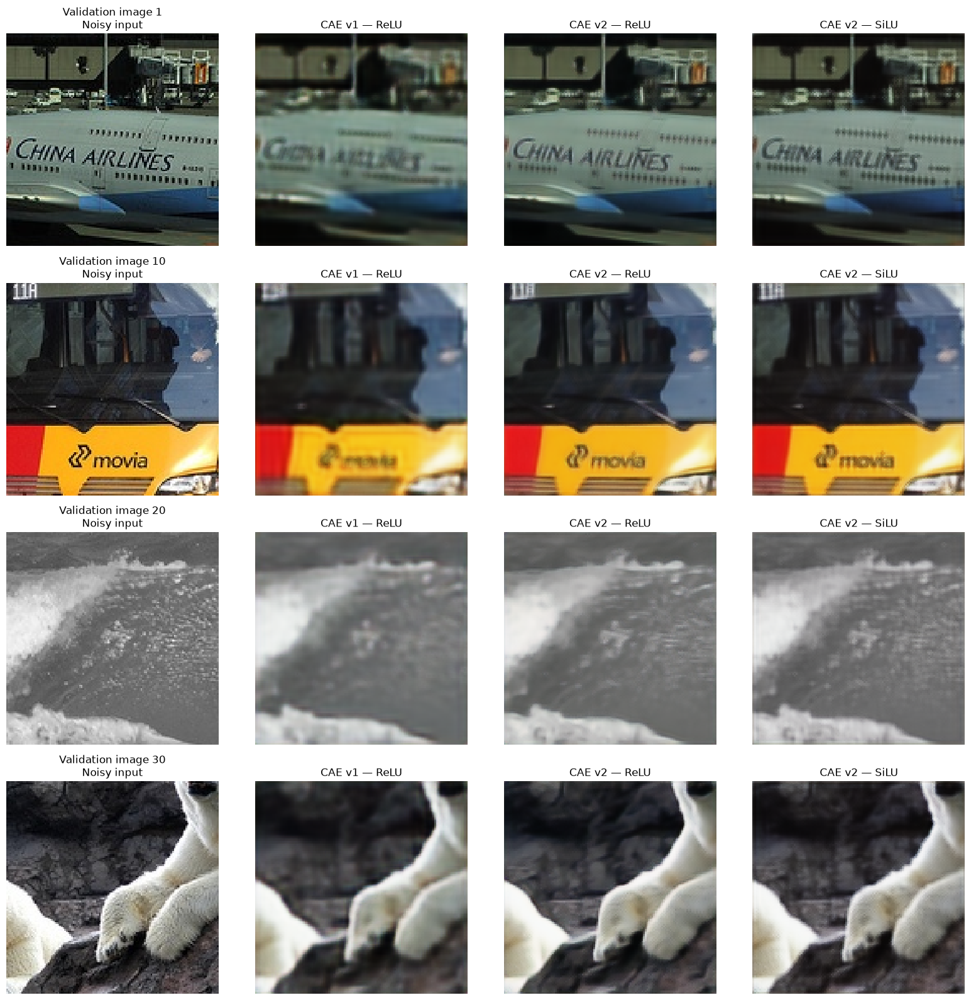

In [23]:
# Case study — comparación final v1, v2 ReLU y v2 SiLU
# Mismas máscaras y mismos vecinos para los tres modelos

def estimate_with_model(image, selected_model, masks, masked_inputs):
    predictions = selected_model.predict(
        masked_inputs,
        batch_size=16,
        verbose=0
    )

    # Conservar solo predicciones de posiciones ocultas
    prediction_sum = np.sum(predictions * masks, axis=0)
    prediction_count = np.sum(masks, axis=0)

    averaged_predictions = (
        prediction_sum / np.maximum(prediction_count, 1.0)
    )

    # Si alguna posición no recibió predicciones, conservar el original
    result = image.copy()
    covered = prediction_count[..., 0] > 0
    result[covered] = averaged_predictions[covered]

    return np.clip(result, 0.0, 1.0)


n_examples = min(4, len(val_images))
example_indices = np.linspace(
    0, len(val_images) - 1, n_examples, dtype=int
)

fig, axes = plt.subplots(
    n_examples,
    4,
    figsize=(16, 4 * n_examples),
    squeeze=False
)

for row, index in enumerate(example_indices):
    image = np.asarray(val_images[index], dtype=np.float32)
    image_tensor = tf.convert_to_tensor(image)
    height, width, _ = image.shape

    rng = np.random.default_rng(42 + int(index))
    n_passes = 200

    masks = (
        rng.random((n_passes, height, width, 1)) < MASK_RATE
    ).astype(np.float32)

    # Elegir vecinos con la misma función utilizada al entrenar.
    # Las semillas permiten repetir esta comparación.
    neighbors = np.stack([
        choose_random_neighbor(
            image_tensor,
            seed=tf.constant(
                [2026 + int(index), pass_index],
                dtype=tf.int32
            )
        ).numpy()
        for pass_index in range(n_passes)
    ])

    # Preparar las entradas una sola vez para los tres modelos
    masked_inputs = (
        image[None, ...] * (1.0 - masks)
        + neighbors * masks
    )

    result_v1 = estimate_with_model(
        image, model, masks, masked_inputs
    )
    result_v2 = estimate_with_model(
        image, model_v2, masks, masked_inputs
    )
    result_silu = estimate_with_model(
        image, model_v2_silu, masks, masked_inputs
    )

    panels = [
        (image, f"Validation image {index + 1}\nNoisy input"),
        (result_v1, "CAE v1 — ReLU"),
        (result_v2, "CAE v2 — ReLU"),
        (result_silu, "CAE v2 — SiLU")
    ]

    for ax, (result, title) in zip(axes[row], panels):
        ax.imshow(result, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")

    coverage = np.mean(np.sum(masks, axis=0)[..., 0] > 0)
    print(
        f"Imagen {index + 1}: cobertura {coverage:.2%} "
        "— mismas entradas para los tres modelos"
    )

plt.tight_layout()
plt.show()

### Qualitative comparison of CAE v1 and CAE v2

Using the same validation images and masking patterns, CAE v2 (U-Net-style) appears to preserve some edges and fine details better than CAE v1, whose outputs look noticeably smoother. The improvement is modest and is not consistent enough to claim that v2 produces a clearly superior restored image in every case.

The comparison is qualitative. Since no clean reference images are available, we cannot objectively measure restoration quality or confirm that the remaining noise has been reduced. The results suggest that the U-Net-style skip connections may help preserve spatial detail, but further validation with clean references or an appropriate independent evaluation would be needed to support a stronger conclusion.

Overall, CAE v2 is the more promising of the two tested models in this visual comparison, but the denoising result remains limited and should be interpreted cautiously.

In the visual comparison, CAE v2 (U-Net-style) preserves edges and fine details better than CAE v1, whose output is noticeably over-smoothed. CAE v2 appears slightly smoother than the noisy input, but without clean reference images, we cannot objectively confirm the amount of noise removed. Therefore, the observed improvement is qualitative and should be interpreted cautiously.

## 4. Results and limitations

### Experimental setup

The experiments use RGB central crops of 128 × 128 pixels, normalised to the range [0, 1]. The random masking probability is 25%. Selected input pixels are replaced with neighbouring pixel values, and the loss is calculated only at masked positions.

Training masks vary during training. Validation masks and neighbour replacements are fixed and reproducible.

### Results

In [24]:
# Comparación final con la validación fija

print(f"CAE v1  (básico)      : {model.evaluate(val_dataset, verbose=0):.6f}")
print(f"CAE v2  (ReLU)        : {model_v2.evaluate(val_dataset, verbose=0):.6f}")
print(f"CAE v2  (SiLU)        : {model_v2_silu.evaluate(val_dataset, verbose=0):.6f}")

CAE v1  (básico)      : 0.004254
CAE v2  (ReLU)        : 0.002645
CAE v2  (SiLU)        : 0.003083



### Interpretation of the results

The baseline CAE and the U-Net-style variants were explored to investigate the balance between masked-pixel prediction and preservation of image detail.

A lower masked validation MSE indicates better prediction of the observed noisy targets at hidden positions. It does not, by itself, demonstrate better noise removal or better perceptual image quality.

The final quantitative comparison must evaluate all retained models in their final state using the same validation dataset. Results recorded before additional training should not be combined with later evaluations as if they represented the same model state.

### Limitations

No clean reference images are available, so restoration PSNR and SSIM against clean targets cannot be reported.

The available data are limited to 148 images, with one central crop used per image. The validation set was used during model development, and no independent test set was reserved.

The masked-denoising approach relies on assumptions about the noise and the information available in neighbouring pixels. These assumptions have not been established for this dataset.

In [25]:
## 5. Model export / Saving

model_v2.save("modelo_denoising_cae_v2_final.keras")
model_v2_silu.save("modelo_denoising_cae_v2_silu.keras")
print("Modelos guardados exitosamente.")

Modelos guardados exitosamente.


## Final conclusions

After the last training round (data augmentation and longer training), CAE v2 with U-Net-style skip connections remains the best model: it preserves text, edges and fine detail, while CAE v1 produces strongly over-smoothed outputs.

The key limitation is now documented rather than hidden: trained to predict masked pixels of already-noisy images, CAE v2 tends to reproduce its input almost identically, so visible noise reduction could not be demonstrated. CAE v1 does transform the image, but at the cost of destroying detail.

With 148 noisy images and no clean references, this outcome is consistent with the limits of self-supervised masked denoising on small datasets. Future work would require either clean reference images (supervised training with PSNR/SSIM evaluation), paired noisy captures (Noise2Noise), or a larger dataset for Noise2Void-style training.